In [1]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd

credit = fetch_ucirepo(id=144)   # Statlog German Credit Data

X = credit.data.features
y = credit.data.targets

df = pd.concat([X, y], axis=1)
print(df.shape)
print(df.isnull().sum().sum(), "missing values")
print(df.iloc[:, -1].value_counts())
df.head()

(1000, 21)
0 missing values
class
1    700
2    300
Name: count, dtype: int64


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [2]:
df.columns = [
    'checking_account', 'duration_months', 'credit_history', 'purpose',
    'credit_amount', 'savings_account', 'employment_since', 'installment_rate',
    'personal_status', 'other_debtors', 'residence_since', 'property',
    'age', 'other_installments', 'housing', 'existing_credits',
    'job', 'dependents', 'telephone', 'foreign_worker', 'class'
]

# Target: 1 = good credit (creditworthy), 0 = bad credit
df['target'] = (df['class'] == 1).astype(int)
df = df.drop('class', axis=1)

print(df['target'].value_counts())
df.info()

target
1    700
0    300
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   checking_account    1000 non-null   object
 1   duration_months     1000 non-null   int64 
 2   credit_history      1000 non-null   object
 3   purpose             1000 non-null   object
 4   credit_amount       1000 non-null   int64 
 5   savings_account     1000 non-null   object
 6   employment_since    1000 non-null   object
 7   installment_rate    1000 non-null   int64 
 8   personal_status     1000 non-null   object
 9   other_debtors       1000 non-null   object
 10  residence_since     1000 non-null   int64 
 11  property            1000 non-null   object
 12  age                 1000 non-null   int64 
 13  other_installments  1000 non-null   object
 14  housing             1000 non-null   object
 15  existing_credits    10

In [3]:
# New features
df['monthly_payment'] = df['credit_amount'] / df['duration_months']   # how much is paid per month
df['long_loan'] = (df['duration_months'] > 24).astype(int)            # 1 = loan longer than 2 years
df['young_borrower'] = (df['age'] < 25).astype(int)                   # 1 = under 25

# Drop gender-related column
df = df.drop('personal_status', axis=1)

# Convert text columns to numbers
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

print(df_encoded.shape)
df_encoded[['credit_amount', 'duration_months', 'monthly_payment', 'long_loan', 'young_borrower', 'target']].head()

(1000, 49)


,credit_amount,duration_months,monthly_payment,long_loan,young_borrower,target
0,1169,6,194.833333,0,0,1
1,5951,48,123.979167,1,1,0
2,2096,12,174.666667,0,0,1
3,7882,42,187.666667,1,0,1
4,4870,24,202.916667,0,0,0


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

X = df_encoded.drop('target', axis=1)
y = df_encoded['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.665,0.829,0.657,0.733,0.741
1,Decision Tree,0.620,0.840,0.564,0.675,0.685
2,Random Forest,0.735,0.764,0.900,0.826,0.776


In [5]:
from sklearn.model_selection import cross_val_score

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring='roc_auc')
    print(f"{name}: {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: 0.783 (+/- 0.024)
Decision Tree: 0.732 (+/- 0.014)
Random Forest: 0.793 (+/- 0.017)


              precision    recall  f1-score   support

  Bad Credit       0.60      0.35      0.44        60
 Good Credit       0.76      0.90      0.83       140

    accuracy                           0.73       200
   macro avg       0.68      0.62      0.63       200
weighted avg       0.71      0.73      0.71       200



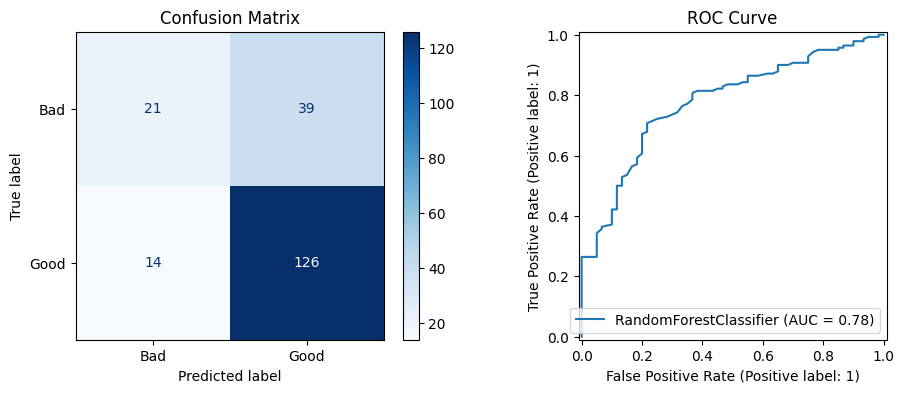

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

final_model = models['Random Forest']
pred = final_model.predict(X_test)

print(classification_report(y_test, pred, target_names=['Bad Credit', 'Good Credit']))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Bad', 'Good'], cmap='Blues', ax=ax[0])
RocCurveDisplay.from_estimator(final_model, X_test, y_test, ax=ax[1])
ax[0].set_title('Confusion Matrix')
ax[1].set_title('ROC Curve')
plt.show()

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import joblib, sklearn
from google.colab import files

X_raw = df.drop('target', axis=1)
y_raw = df['target']
cat_cols = X_raw.select_dtypes(include='object').columns.tolist()

Xtr, Xte, ytr, yte = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42, stratify=y_raw)

final_model = make_pipeline(
    ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)], remainder='passthrough'),
    RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
)
final_model.fit(Xtr, ytr)

print('Accuracy:', round(accuracy_score(yte, final_model.predict(Xte)), 3))
print('ROC-AUC :', round(roc_auc_score(yte, final_model.predict_proba(Xte)[:, 1]), 3))
print('scikit-learn version:', sklearn.__version__)

joblib.dump(final_model, 'credit_model.pkl')
joblib.dump(list(X_raw.columns), 'features.pkl')
files.download('credit_model.pkl')
files.download('features.pkl')

Accuracy: 0.745
ROC-AUC : 0.779
scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>